# 02 · Benchmark results

Held-out **test** split (sampled parameters, unseen data seeds) unless noted. Produced by `kpi-detective benchmark --split test` and `python -m kpi_detective.evaluation.evaluate_detection`.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25})
res = ROOT / 'results'
summary = pd.read_csv(res / 'test' / 'summary.csv')
summary.style.format({c: '{:.1%}' for c in summary.columns if summary[c].dtype == float and c not in
                      ('avg_steps', 'avg_latency_s', 'avg_cost_usd')} | {'avg_steps': '{:.1f}', 'avg_latency_s': '{:.2f}'})

,system,scenarios,top1_accuracy,top3_accuracy,top1_segment_only,classification_accuracy,false_alarm_handling,unsupported_claim_rate,avg_steps,avg_cost_usd,avg_latency_s,consistency
0,rule_based,60,0.0%,0.0%,41.7%,58.3%,0.0%,0.0%,5.0,0.000000,0.08,nan%
1,playbook,60,85.0%,76.7%,86.7%,86.7%,72.7%,0.0%,7.9,0.000000,0.27,nan%
2,playbook_no_critic,60,85.0%,76.7%,86.7%,86.7%,72.7%,0.0%,7.9,0.000000,0.26,nan%


## Dev vs test

The playbook rules were written while looking at the dev scenarios, so dev accuracy is optimistic. The gap between the two rows is the honest measure of over-fitting.

In [2]:
both = pd.concat({sp: pd.read_csv(res / sp / 'summary.csv').set_index('system') for sp in ['dev', 'test']})
both[['top1_accuracy', 'top3_accuracy', 'top1_segment_only', 'classification_accuracy', 'false_alarm_handling']].style.format('{:.0%}')

## Accuracy by incident type

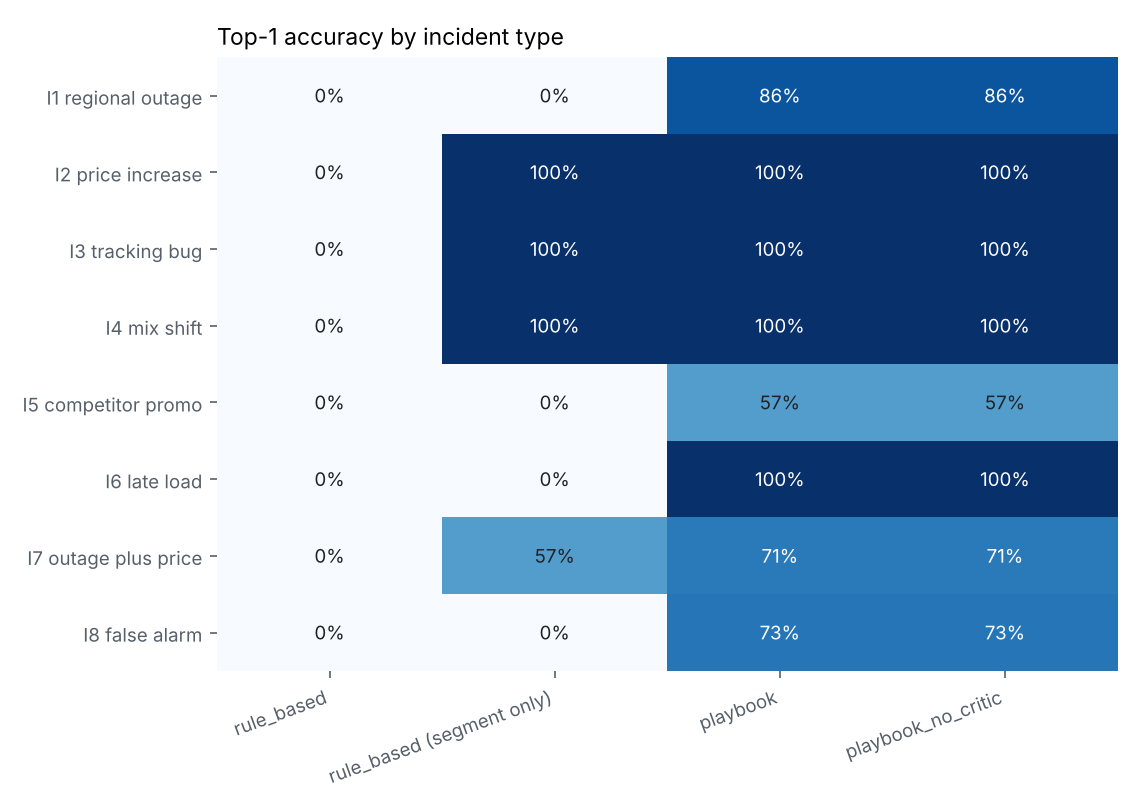

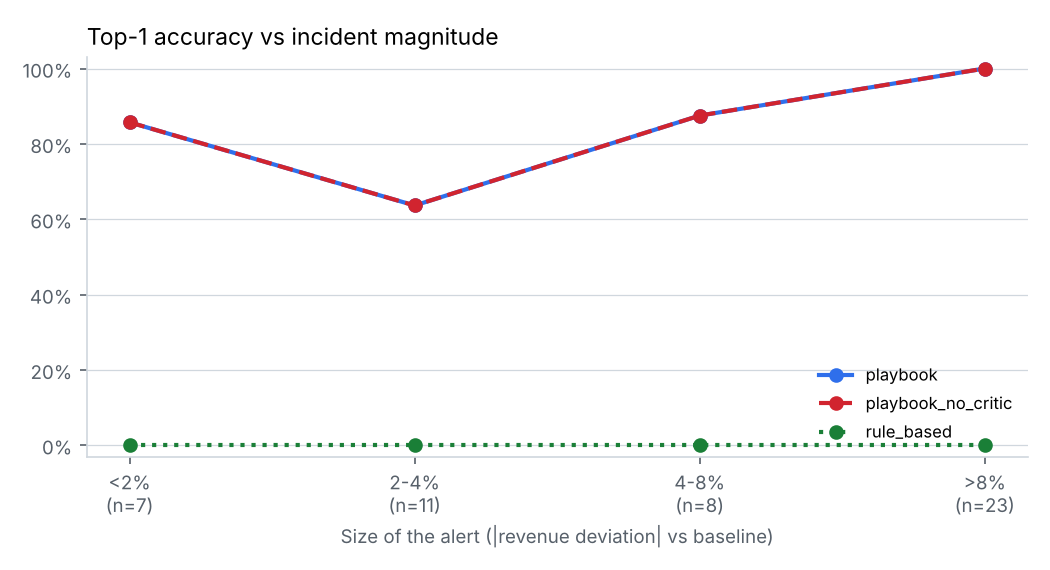

In [3]:
from IPython.display import Image, display
display(Image(res / 'test' / 'heatmap_top1_by_incident.png', width=650))
display(Image(res / 'test' / 'accuracy_vs_magnitude.png', width=650))

## Detection layer

,recall_I1_I7,false_positive_rate_I8
naive_4w_baseline,53%,100%
stl_robust_z,57%,45%
forecast_pi95,82%,18%


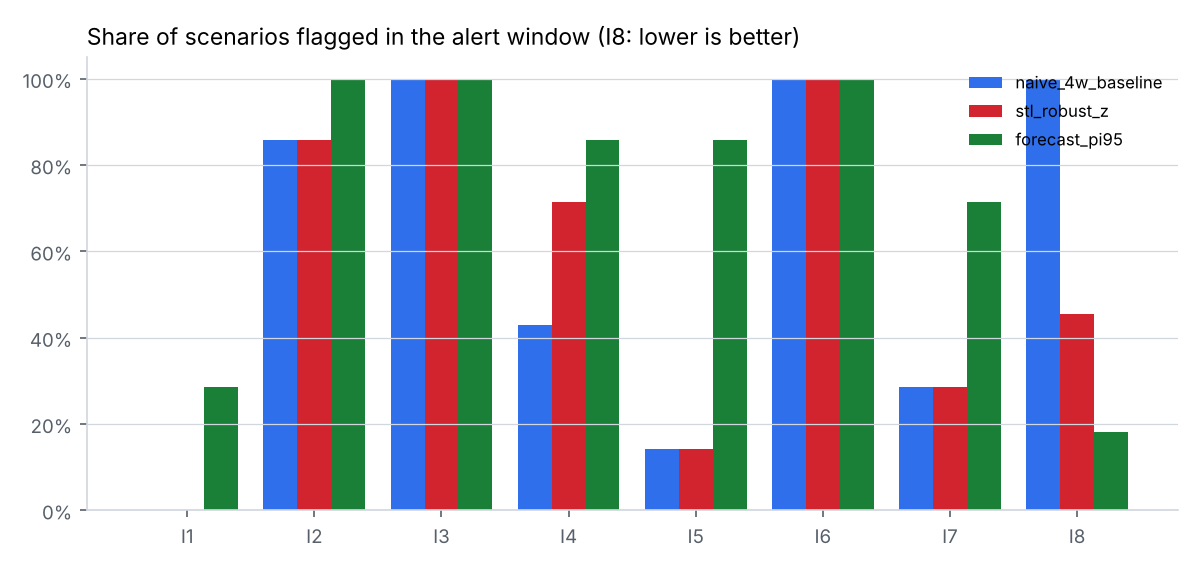

In [4]:
det = pd.read_csv(res / 'test' / 'detection_summary.csv', index_col=0)
display(det.style.format('{:.0%}'))
display(Image(res / 'test' / 'detection_by_incident_type.png', width=650))

## Failures on the test split

Every miss of the full playbook, with what it answered instead.

In [5]:
rec = pd.read_csv(res / 'test' / 'records.csv')
pb = rec[(rec['system'] == 'playbook') & ~rec['top1']]
import json
desc = {p.stem: json.loads(p.read_text())['description'] for p in (ROOT / 'data/scenarios/test').glob('*.json')}
pb.assign(planted=pb['scenario_id'].map(desc))[['scenario_id', 'planted', 'magnitude', 'classification', 'top_cause', 'top_mechanism']]

,scenario_id,planted,magnitude,classification,top_cause,top_mechanism
13,TI1_05,"Online outage in India, -62% for 2d",0.0216,inconclusive,"{""region"": ""NA"", ""customer_segment"": ""Enterpri...",mix
85,TI5_01,Monitors in NA decline gradually to -82% over 10d,0.0403,business_change,"{""country"": ""US"", ""product_category"": ""Monitors""}",volume
100,TI5_06,Monitors in APAC decline gradually to -61% ove...,0.0291,business_change,"{""region"": ""APAC""}",volume
103,TI5_07,Monitors in LATAM decline gradually to -68% ov...,0.0039,inconclusive,NaN,NaN
127,TI7_01,Online outage in UK + Monitors price +10%,0.0222,inconclusive,"{""product_category"": ""Monitors""}",NaN
130,TI7_02,Online outage in Canada + Monitors price +9%,0.0314,business_change,"{""channel"": ""Online""}",volume
151,TI8_02,"Normal seasonal dip, nothing injected",0.2990,inconclusive,NaN,NaN
157,TI8_04,"Normal seasonal dip, nothing injected",0.2970,business_change,"{""customer_segment"": ""Consumer""}",volume
160,TI8_05,"Normal seasonal dip, nothing injected",0.0932,business_change,"{""channel"": ""Direct Sales"", ""customer_segment""...",volume


Nine misses, three patterns (details in the README):

1. **Small alerts (5 of 9)**: TI1_05, TI5_06, TI5_07, TI7_01 and TI7_02 all have alerts of 3.1% or less, against roughly 1.3% noise. Segment drops are real but not significant, or the 12-call budget runs out before the second cause of an I7 is confirmed.
2. **Dominant child ambiguity (1 of 9)**: in TI5_01 the US is about 85% of NA, so a drop in NA monitors is just as concentrated in US monitors and the playbook stops one level too deep.
3. **Seasonal dips that differ from last year (3 of 9)**: TI8_02, TI8_04 and TI8_05. When last year's dip explains too little of this year's, the segment that carries the seasonal effect (Consumer after Christmas, Enterprise after quarter end) gets confirmed and reported as a business cause. Year-over-year comparison per segment is the fix.